<a href="https://colab.research.google.com/github/liaalcantara01/CDA-UTEC/blob/main/Lab9_3_TAREA_Racarumi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 9.3 · RNN y LSTM — Chancay–Lambayeque
### Ciencia de Datos Ambientales | Entrega de los ejercicios 1 al 4

**Cuenca de estudio:** Chancay–Lambayeque (vertiente del Pacífico, Perú)  
**Estación:** Racarumi | **Código CAMELS-PE:** `PE_200907`  
**Fuente de datos:** CAMELS-PE v1.0.1 (SENAMHI)  
**Períodos:** entrenamiento 1998–2010; validación 2011–2015; prueba 2016–2020.  
**Referencia metodológica:** notebook docente `Lab9_3_RNN_LSTM_Peru_v2.ipynb`.

**Objetivo.** Aplicar los procedimientos de simulación lluvia–escorrentía y pronóstico de caudal mediante redes RNN y LSTM, evaluando memoria temporal, variables estacionales, ensamble y horizontes de pronóstico en una cuenca diferente a la utilizada en el ejemplo de clase.



## 1. Datos y diseño metodológico

Se emplean datos diarios de precipitación (`prec`), temperaturas media/máxima/mínima (`tmean`, `tmax`, `tmin`), radiación solar (`srad`), presión de vapor (`vprp`), caudal observado (`flow_obs`) y caudal simulado PISCO-ARNOVIC (`flow_sim`). Los caudales se expresan en **mm/día** de lámina equivalente de escorrentía, como en el laboratorio docente.

| Componente | Configuración |
|---|---|
| Cuenca / estación | Chancay–Lambayeque / Racarumi (`PE_200907`) |
| Entrenamiento | 1998–2010 |
| Validación | 2011–2015 |
| Prueba | 2016–2020 |
| Datos antecedentes | Desde 1996 para construir ventanas temporales |
| Variables meteorológicas | `prec`, `tmean`, `tmax`, `tmin`, `srad`, `vprp` |
| Redes recurrentes | `SimpleRNN(32)` y `LSTM(32)` |
| Salida de simulación | Log-caudal normalizado, posteriormente revertido a mm/día |
| Optimizador / pérdida | Adam (0.001) / MSE |
| Regularización | `Dropout(0.2)` y *early stopping* (paciencia 6) |
| Épocas máximas / lote | 40 / 128 |
| Evaluación | NSE y KGE, siempre sobre el período de prueba |

La estructura de modelos, horizontes y experimentos se conserva del cuaderno del docente. Se incorporan controles técnicos para verificar la integridad del CSV, evitar mezclar fechas de distintos períodos e impedir que los faltantes de caudal se conviertan en objetivos de entrenamiento.

**Fuente:** Llauca et al. (2026), CAMELS-PE v1.0.1: https://doi.org/10.5281/zenodo.21195425.
**Fuente de los datos:** CAMELS-PE v1.0.1, Zenodo. La serie diaria `PE_200907.csv` se consulta directamente dentro del ZIP alojado en Zenodo mediante solicitudes parciales (HTTP Range); no se descarga el archivo nacional completo.


In [1]:
# 1.1 Bibliotecas y configuración
import os, time, io, re, zipfile, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import tensorflow as tf
except ModuleNotFoundError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow'])
    import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
keras.utils.set_random_seed(42)
plt.rcParams.update({'figure.figsize': (11, 4.8), 'font.size': 10})

GAUGE = 'PE_200907'
CUENCA = 'Chancay–Lambayeque'
ESTACION = 'Racarumi'
ARCHIVO = f'{GAUGE}.csv'
RAIZ = Path('/content') if Path('/content').is_dir() else Path.cwd()
DIRECTORIO_RESULTADOS = RAIZ / 'resultados_chancay_lambayeque'
DIRECTORIO_RESULTADOS.mkdir(parents=True, exist_ok=True)
print(f'Caso de estudio: cuenca {CUENCA} | estación {ESTACION} ({GAUGE})')
print('TensorFlow:', tf.__version__)

Caso de estudio: cuenca Chancay–Lambayeque | estación Racarumi (PE_200907)
TensorFlow: 2.21.0


In [ ]:
# 1.2 Conexión directa a CAMELS-PE v1.0.1 (Zenodo) y extracción selectiva de Racarumi
from pathlib import Path
import subprocess
import sys
import shutil

try:
    from remotezip import RemoteZip
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'remotezip'])
    from remotezip import RemoteZip

URL_CAMELS_PE = 'https://zenodo.org/records/21195425/files/CAMELS-PE_v1.0.1.zip'
ruta = RAIZ / ARCHIVO

if not ruta.is_file():
    print('Conectando con CAMELS-PE v1.0.1 para recuperar únicamente', ARCHIVO)
    try:
        with RemoteZip(URL_CAMELS_PE, timeout=90) as z:
            coincidencias = [nombre for nombre in z.namelist()
                            if nombre.replace('\\', '/').endswith('/03_timeseries/by_catchment/' + ARCHIVO)]
            if len(coincidencias) != 1:
                raise FileNotFoundError(f'No se localizó un único {ARCHIVO} en 03_timeseries/by_catchment/')
            nombre_remoto = coincidencias[0]
            with z.open(nombre_remoto) as origen, ruta.open('wb') as destino:
                shutil.copyfileobj(origen, destino)
    except Exception as exc:
        if ruta.exists():
            ruta.unlink()
        raise RuntimeError(
            'No se pudo consultar el CSV dentro del ZIP de Zenodo mediante solicitudes parciales. '
            'Comprueba el acceso a internet de Colab y vuelve a ejecutar esta celda. '
            'El notebook NO descargó el conjunto completo como alternativa.'
        ) from exc

print('Estación:', ESTACION, '| Código:', GAUGE)
print('Datos de serie disponibles en:', ruta)
print('Tamaño de CSV recuperado: {:.2f} MB'.format(ruta.stat().st_size / 1e6))


Conectando con CAMELS-PE v1.0.1 para recuperar únicamente PE_200907.csv
Estación: Racarumi | Código: PE_200907
Datos de serie disponibles en: /content/PE_200907.csv
Tamaño de CSV recuperado: 1.21 MB


In [ ]:
# 1.3 Lectura, validación de cuenca y disponibilidad temporal
camels = pd.read_csv(ruta, low_memory=False)
camels.columns = camels.columns.astype(str).str.strip().str.lower()
VARS_MET = ['prec', 'tmean', 'tmax', 'tmin', 'srad', 'vprp']
CAMPOS = ['date'] + VARS_MET + ['flow_obs', 'flow_sim']
faltan = [x for x in CAMPOS if x not in camels]
if faltan:
    raise ValueError('El CSV no contiene las columnas requeridas: ' + ', '.join(faltan))
if 'gauge_id' in camels:
    ids = set(camels['gauge_id'].dropna().astype(str).str.strip())
    if ids and ids != {GAUGE}:
        raise ValueError(f'Inconsistencia de estación: esperado {GAUGE}, encontrado {ids}')
camels['date'] = pd.to_datetime(camels['date'], errors='coerce')
camels = (camels.dropna(subset=['date']).drop_duplicates('date')
                .set_index('date').sort_index())
for v in VARS_MET + ['flow_obs', 'flow_sim']:
    camels[v] = pd.to_numeric(camels[v], errors='coerce')
for v in ['flow_obs','flow_sim']:
    camels.loc[camels[v] < 0, v] = np.nan

print(f'Cuenca: {CUENCA} | Estación: {ESTACION} | Código: {GAUGE}')
print(f'Período disponible: {camels.index.min().date()} a {camels.index.max().date()}')
print(f'Total registros: {len(camels):,} | caudal observado: {camels.flow_obs.notna().sum():,}')

periodos_tabla = []
for nombre,ini,fin in [('Entrenamiento','1998-01-01','2010-12-31'),
                       ('Validación','2011-01-01','2015-12-31'),
                       ('Prueba','2016-01-01','2020-12-31')]:
    v = camels.loc[ini:fin]
    n_total = len(pd.date_range(ini,fin))
    periodos_tabla.append({'Período':nombre,'Desde':ini,'Hasta':fin,
                           'Días calendario':n_total,'Caudal observado':int(v.flow_obs.notna().sum()),
                           'Disponibilidad (%)':round(100 * v.flow_obs.notna().sum()/n_total,1)})
cobertura = pd.DataFrame(periodos_tabla)
display(cobertura)
cobertura.to_csv(DIRECTORIO_RESULTADOS / '00_cobertura_periodos.csv',index=False)

if (cobertura['Caudal observado'] < 365).any():
    raise ValueError('La estación seleccionada no tiene suficientes datos observados en alguno '
                     'de los tres períodos. El análisis se detiene sin sustituir la cuenca.')

Cuenca: Chancay–Lambayeque | Estación: Racarumi | Código: PE_200907
Período disponible: 1981-01-01 a 2025-12-31
Total registros: 16,436 | caudal observado: 15,533


,Período,Desde,Hasta,Días calendario,Caudal observado,Disponibilidad (%)
0,Entrenamiento,1998-01-01,2010-12-31,4748,4731,99.6
1,Validación,2011-01-01,2015-12-31,1826,1824,99.9
2,Prueba,2016-01-01,2020-12-31,1827,1827,100.0


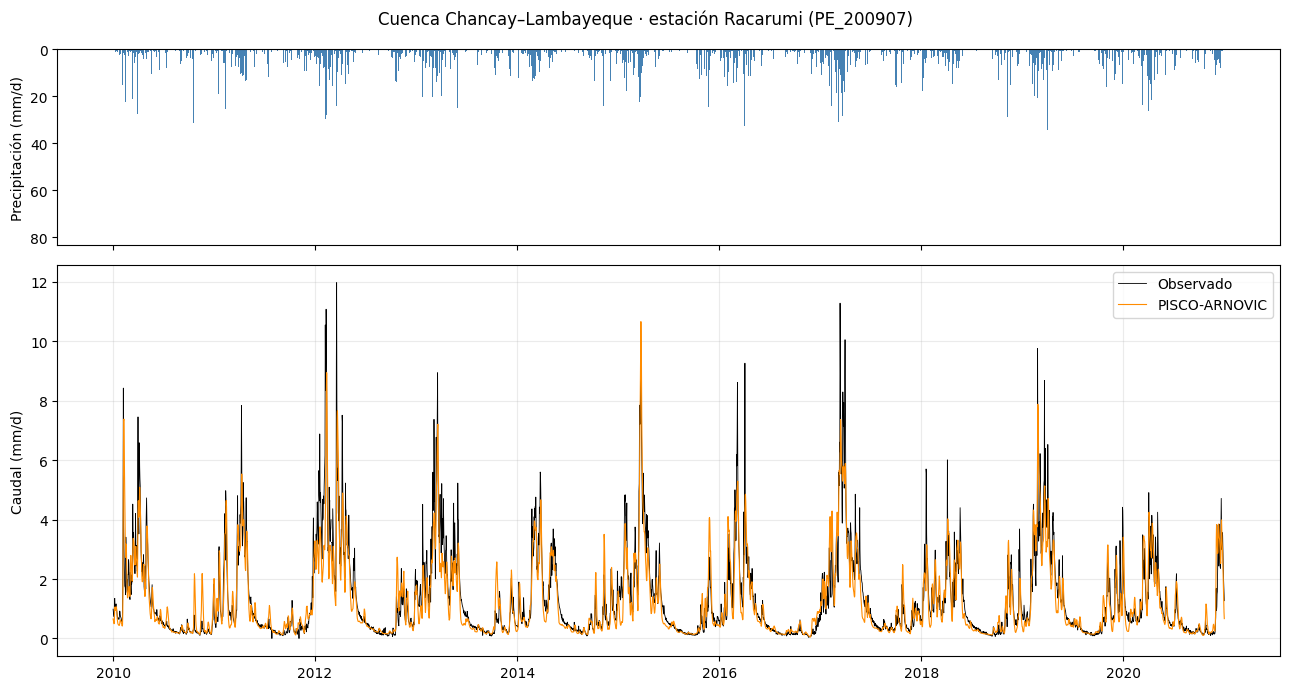

,Período,NSE,KGE
0,Entrenamiento,0.728,0.856
1,Validación,0.803,0.801
2,Prueba,0.814,0.872


In [ ]:
# 1.4 NSE, KGE y gráfico hidrológico original adaptado a la cuenca de estudio
def _pares_validos(obs, sim):
    a, b = np.asarray(obs, float), np.asarray(sim, float)
    m = np.isfinite(a) & np.isfinite(b)
    return a[m], b[m]

def nse(obs, sim):
    o, p = _pares_validos(obs, sim)
    if len(o) < 2 or np.sum((o - o.mean())**2) <= 0: return np.nan
    return 1 - np.sum((o-p)**2) / np.sum((o-o.mean())**2)

def kge(obs, sim):
    o, p = _pares_validos(obs, sim)
    if len(o) < 3 or o.std() <= 0 or o.mean() <= 0: return np.nan
    r = np.corrcoef(o,p)[0,1] if p.std() > 0 else np.nan
    if not np.isfinite(r): return np.nan
    return 1 - np.sqrt((r-1)**2 + (p.std()/o.std()-1)**2 + (p.mean()/o.mean()-1)**2)

tramo = camels.loc['2010':'2020']
fig, axes = plt.subplots(2,1,figsize=(13,7),sharex=True, gridspec_kw={'height_ratios':[1,2]})
axes[0].bar(tramo.index,tramo.prec,width=1,color='steelblue')
axes[0].invert_yaxis(); axes[0].set_ylabel('Precipitación (mm/d)')
axes[1].plot(tramo.index,tramo.flow_obs,'k-',lw=.6,label='Observado')
axes[1].plot(tramo.index,tramo.flow_sim,color='darkorange',lw=.8,label='PISCO-ARNOVIC')
axes[1].set_ylabel('Caudal (mm/d)');axes[1].legend();axes[1].grid(alpha=.25)
fig.suptitle(f'Cuenca {CUENCA} · estación {ESTACION} ({GAUGE})')
plt.tight_layout(); fig.savefig(DIRECTORIO_RESULTADOS/'00_series_hidrologicas.png',dpi=160);plt.show()

tabla_arnovic = []
for nombre,ini,fin in [('Entrenamiento','1998','2010'),('Validación','2011','2015'),('Prueba','2016','2020')]:
    tramo = camels.loc[ini:fin]
    tabla_arnovic.append({'Período':nombre,'NSE':nse(tramo.flow_obs,tramo.flow_sim),
                          'KGE':kge(tramo.flow_obs,tramo.flow_sim)})
tabla_arnovic = pd.DataFrame(tabla_arnovic)
display(tabla_arnovic.round(3))
tabla_arnovic.to_csv(DIRECTORIO_RESULTADOS/'00_arnovic_por_periodo.csv',index=False)

In [ ]:
# 1.5 Preprocesamiento y construcción de ventanas (misma lógica del laboratorio docente)
df = camels.loc['1996-01-01':'2020-12-31'].copy()
fechas = pd.date_range('1996-01-01','2020-12-31',freq='D')
df = df.reindex(fechas)
df.index.name = 'date'
entrena = df.index <= '2010-12-31'

# Las estadísticas de entrada y salida se obtienen solo del período de entrenamiento.
medias = df.loc[entrena, VARS_MET].mean()
desv = df.loc[entrena, VARS_MET].std(ddof=0)
if medias.isna().any() or (desv <= 0).any() or desv.isna().any():
    raise ValueError('No se puede normalizar alguna variable meteorológica en el período de entrenamiento.')
if df[VARS_MET].isna().any().any():
    print('Datos meteorológicos faltantes: imputación mediante la media del entrenamiento.')
X_met = df[VARS_MET].fillna(medias).values.astype('float32')
X_met_n = ((X_met - medias.values) / desv.values).astype('float32')

q_obs = df.flow_obs.to_numpy(dtype=float)
q_log = np.log(q_obs + 0.05)
q_media, q_desv = np.nanmean(q_log[entrena]), np.nanstd(q_log[entrena])
if not np.isfinite(q_media) or not np.isfinite(q_desv) or q_desv <= 0:
    raise ValueError('No es posible normalizar el caudal observado del entrenamiento.')
q_n = (q_log - q_media) / q_desv

def a_caudal(v):
    return np.maximum(np.exp(np.asarray(v) * q_desv + q_media) - 0.05, 0)

def crear_ventanas(X, ventana, horizonte=0):
    # Igual que en clase: X termina en t; el objetivo corresponde al día t+horizonte.
    t = np.arange(ventana-1,len(X)-horizonte)
    t = t[np.isfinite(q_obs[t+horizonte]) & (df.index[t] >= '1998-01-01')]
    if len(t) == 0: raise ValueError(f'No existen ventanas válidas con longitud {ventana} y horizonte {horizonte}.')
    Xw = np.stack([X[i-ventana+1:i+1] for i in t]).astype('float32')
    f = df.index[t+horizonte]
    periodos = {'entrena':np.asarray(f <= '2010-12-31'),
                'valida': np.asarray((f > '2010-12-31') & (f <= '2015-12-31')),
                'prueba':np.asarray(f >= '2016-01-01')}
    if min(mask.sum() for mask in periodos.values()) == 0:
        raise ValueError(f'No hay datos en algún período para ventana {ventana} y horizonte {horizonte}')
    return Xw,t,f,periodos

EPOCAS = 40
BATCH_SIZE = 128

def entrenar(capa,Xw,y,periodos,semilla=42):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    modelo = keras.Sequential([keras.Input(shape=Xw.shape[1:]),capa,
                               layers.Dropout(0.2),layers.Dense(1)])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),loss='mse')
    e,v = periodos['entrena'],periodos['valida']
    inicio = time.time()
    hist = modelo.fit(Xw[e],y[e],epochs=EPOCAS,batch_size=BATCH_SIZE,
                      validation_data=(Xw[v],y[v]),
                      callbacks=[keras.callbacks.EarlyStopping(patience=6,restore_best_weights=True)],
                      verbose=0)
    print(f'{capa.__class__.__name__} · semilla {semilla} · {len(hist.history["loss"])} épocas · {time.time()-inicio:.1f} s')
    return modelo,hist

print(f'Entrada meteorológica: {X_met_n.shape}, caudal observado válido: {np.isfinite(q_obs).sum()} días')

Entrada meteorológica: (9132, 6), caudal observado válido: 9112 días


## 2. Práctica A1: simulación lluvia–escorrentía

La entrada contiene **180 días anteriores de las seis variables meteorológicas** y la salida es el caudal observado del último día de la ventana. Se comparan RNN simple, LSTM y el modelo hidrológico PISCO-ARNOVIC en el conjunto de prueba 2016–2020, conforme al cuaderno original.

Tensor A1: (8382, 180, 6)
{'entrena': 4731, 'valida': 1824, 'prueba': 1827}
SimpleRNN · semilla 42 · 38 épocas · 64.4 s
LSTM · semilla 42 · 11 épocas · 45.9 s


,Modelo,NSE,KGE
0,PISCO-ARNOVIC,0.814,0.872
1,RNN simple (180 d),0.817,0.837
2,LSTM (180 d),0.858,0.886


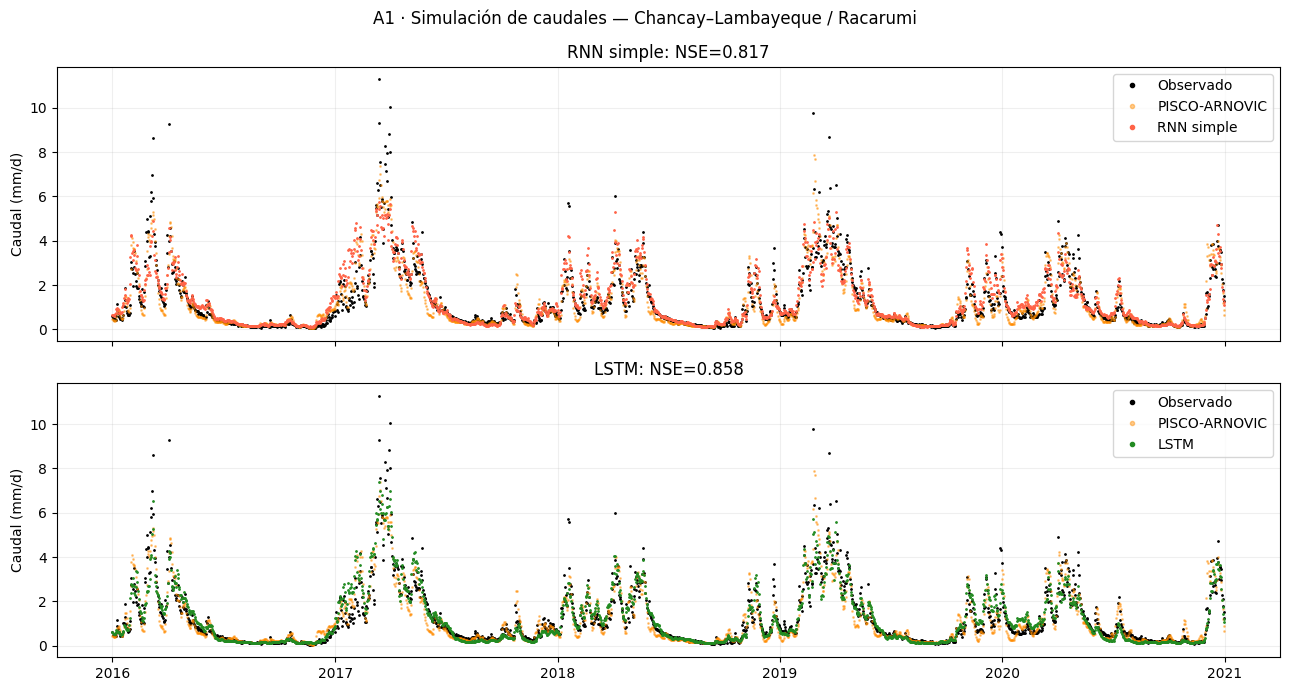

In [ ]:
# 2.1 Modelo original A1 con ventana de 180 días
VENTANA_SIM = 180
Xs, ts, fechas_s, per_s = crear_ventanas(X_met_n,VENTANA_SIM)
ys = q_n[ts].astype('float32')
print('Tensor A1:',Xs.shape)
print({k:int(v.sum()) for k,v in per_s.items()})

rnn_sim,hist_rnn_sim = entrenar(layers.SimpleRNN(32),Xs,ys,per_s)
lstm_sim,hist_lstm_sim = entrenar(layers.LSTM(32),Xs,ys,per_s)

p=per_s['prueba'];obs_te=q_obs[ts][p]
pred_rnn_sim = a_caudal(rnn_sim.predict(Xs[p],verbose=0).ravel())
pred_lstm_sim = a_caudal(lstm_sim.predict(Xs[p],verbose=0).ravel())
sim_arnovic = df.flow_sim.to_numpy()[ts][p]

resultados_A1 = pd.DataFrame([
    {'Modelo':'PISCO-ARNOVIC','NSE':nse(obs_te,sim_arnovic),'KGE':kge(obs_te,sim_arnovic)},
    {'Modelo':'RNN simple (180 d)','NSE':nse(obs_te,pred_rnn_sim),'KGE':kge(obs_te,pred_rnn_sim)},
    {'Modelo':'LSTM (180 d)','NSE':nse(obs_te,pred_lstm_sim),'KGE':kge(obs_te,pred_lstm_sim)}
])
display(resultados_A1.round(3))
resultados_A1.to_csv(DIRECTORIO_RESULTADOS/'01_A1_simulacion_180d.csv',index=False)

fig,axs=plt.subplots(2,1,figsize=(13,7),sharex=True)
for ax,pred,nombre,color in [(axs[0],pred_rnn_sim,'RNN simple','tomato'),
                              (axs[1],pred_lstm_sim,'LSTM','forestgreen')]:
    ax.plot(fechas_s[p],obs_te,'k.',ms=2,label='Observado')
    ax.plot(fechas_s[p],sim_arnovic,'.',color='darkorange',ms=2,alpha=.45,label='PISCO-ARNOVIC')
    ax.plot(fechas_s[p],pred,'.',color=color,ms=2,label=nombre)
    ax.set_ylabel('Caudal (mm/d)');ax.set_title(f'{nombre}: NSE={nse(obs_te,pred):.3f}')
    ax.legend(markerscale=3);ax.grid(alpha=.2)
fig.suptitle(f'A1 · Simulación de caudales — {CUENCA} / {ESTACION}')
plt.tight_layout();fig.savefig(DIRECTORIO_RESULTADOS/'01_A1_simulacion_180d.png',dpi=160);plt.show()

## 3. Ejercicio 1: memoria de la cuenca

**Consigna del laboratorio:** repetir la simulación con `VENTANA_SIM = 30`, `90` y `365`. Evaluar cómo cambia el NSE e interpretar la respuesta temporal de la cuenca.

Se mantiene como referencia el experimento original de 180 días y se comparan las arquitecturas RNN y LSTM con los mismos ajustes de entrenamiento.

SimpleRNN · semilla 42 · 31 épocas · 14.2 s
LSTM · semilla 42 · 11 épocas · 11.4 s
SimpleRNN · semilla 42 · 39 épocas · 35.2 s
LSTM · semilla 42 · 40 épocas · 82.7 s
SimpleRNN · semilla 42 · 40 épocas · 118.6 s
LSTM · semilla 42 · 39 épocas · 299.4 s


,Ventana (días),Modelo,NSE,KGE
0,30,LSTM,0.835,0.870
1,90,LSTM,0.854,0.901
2,180,LSTM,0.858,0.886
3,365,LSTM,0.842,0.852
4,30,RNN,0.854,0.852
5,90,RNN,0.857,0.854
6,180,RNN,0.817,0.837
7,365,RNN,0.860,0.885


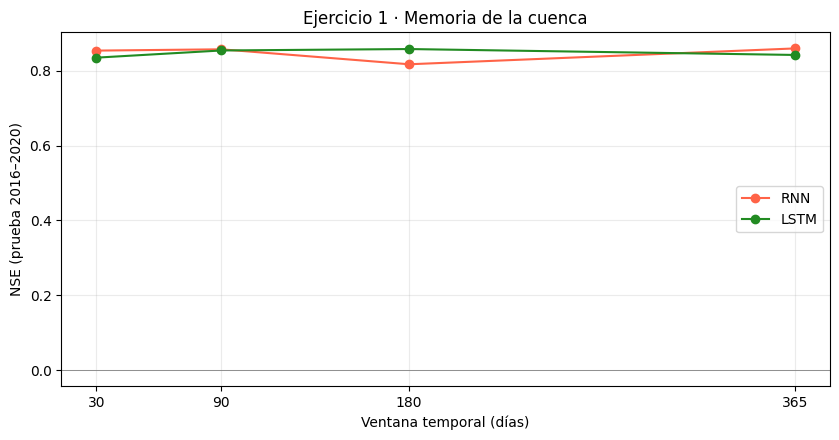

**Interpretación E1.** El NSE más alto de esta comparación fue **0.860**, correspondiente a **RNN con 365 días**. La sensibilidad a la ventana indica cuánta información antecedente resulta útil al modelo para esta estación; no permite determinar por sí sola un tiempo de residencia hidrológico físico.

In [ ]:
# 3.1 Comparación de longitudes de memoria: 30, 90, 180 y 365 días
filas_E1 = [
    {'Ventana (días)':180,'Modelo':'RNN','NSE':nse(obs_te,pred_rnn_sim),'KGE':kge(obs_te,pred_rnn_sim)},
    {'Ventana (días)':180,'Modelo':'LSTM','NSE':nse(obs_te,pred_lstm_sim),'KGE':kge(obs_te,pred_lstm_sim)}]
for ventana in [30,90,365]:
    Xw,tw,fw,pw = crear_ventanas(X_met_n, ventana)
    yw = q_n[tw].astype('float32')
    p = pw['prueba']; obs = q_obs[tw][p]
    for nombre,capa in [('RNN',layers.SimpleRNN(32)),('LSTM',layers.LSTM(32))]:
        modelo,_ = entrenar(capa,Xw,yw,pw)
        pred = a_caudal(modelo.predict(Xw[p],verbose=0).ravel())
        filas_E1.append({'Ventana (días)':ventana,'Modelo':nombre,
                         'NSE':nse(obs,pred),'KGE':kge(obs,pred)})
    del Xw

tabla_E1=pd.DataFrame(filas_E1).sort_values(['Modelo','Ventana (días)']).reset_index(drop=True)
display(tabla_E1.round(3))
tabla_E1.to_csv(DIRECTORIO_RESULTADOS/'02_ejercicio1_memoria_cuenca.csv',index=False)

fig,ax=plt.subplots(figsize=(8.5,4.5))
for nombre,color in [('RNN','tomato'),('LSTM','forestgreen')]:
    t=tabla_E1.query('Modelo==@nombre').sort_values('Ventana (días)')
    ax.plot(t['Ventana (días)'],t.NSE,'o-',label=nombre,color=color)
ax.axhline(0,color='gray',lw=.6);ax.set_xticks([30,90,180,365])
ax.set_xlabel('Ventana temporal (días)');ax.set_ylabel('NSE (prueba 2016–2020)')
ax.set_title('Ejercicio 1 · Memoria de la cuenca');ax.legend();ax.grid(alpha=.25)
plt.tight_layout();fig.savefig(DIRECTORIO_RESULTADOS/'02_ejercicio1_memoria_cuenca.png',dpi=160);plt.show()

mejor_E1=tabla_E1.loc[tabla_E1.NSE.idxmax()]
display(Markdown(
    f'**Interpretación E1.** El NSE más alto de esta comparación fue **{mejor_E1.NSE:.3f}**, '
    f'correspondiente a **{mejor_E1.Modelo} con {int(mejor_E1["Ventana (días)"])} días**. '
    'La sensibilidad a la ventana indica cuánta información antecedente resulta útil al modelo '
    'para esta estación; no permite determinar por sí sola un tiempo de residencia hidrológico físico.'
))

## 4. Ejercicio 2: ingeniería de características + LSTM

**Consigna del laboratorio:** incorporar a las variables meteorológicas representaciones cíclicas del día del año (`sin` y `cos`) **o** `prec_var`, y comprobar si mejora la LSTM.

Se elige la opción de **estacionalidad seno/coseno** explicada en la sección 1.1 del notebook docente. La comparación se realiza con la misma ventana de 180 días, el mismo modelo y la misma partición temporal.

LSTM · semilla 42 · 32 épocas · 126.9 s


,Variables,NSE,KGE
0,Meteorología (6),0.858,0.886
1,Meteorología + seno/coseno (8),0.881,0.918


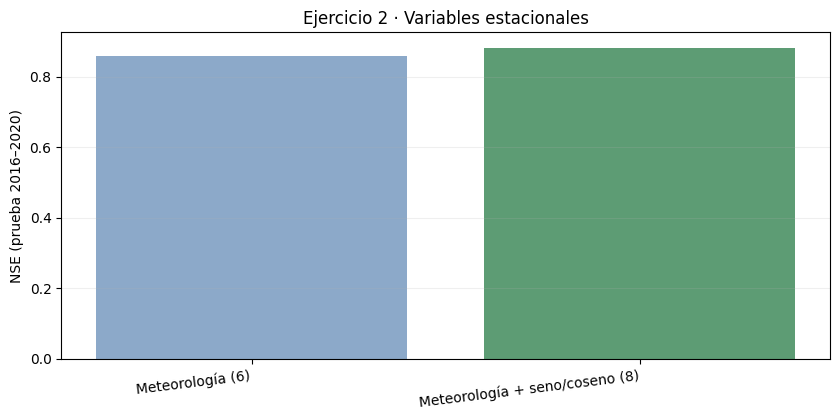

**Interpretación E2.** Las variables cíclicas modificaron el NSE de prueba en **+0.023 puntos** frente a la LSTM meteorológica base. Un incremento implica mejora en esta partición; una disminución indica que la codificación estacional no aportó una mejora generalizable en este ensayo.

In [ ]:
# 4.1 Incorporación de las características cíclicas del día del año
ang=2*np.pi*(df.index.dayofyear.to_numpy()-1)/365.25
estacion_sin=np.sin(ang).astype('float32')
estacion_cos=np.cos(ang).astype('float32')
X_met_est=np.column_stack([X_met_n,estacion_sin,estacion_cos]).astype('float32')
Xe,te,fe,pe=crear_ventanas(X_met_est,180)
ye=q_n[te].astype('float32')
modelo_est,hist_est=entrenar(layers.LSTM(32),Xe,ye,pe)
ptest=pe['prueba'];obs_e=q_obs[te][ptest]
pred_est=a_caudal(modelo_est.predict(Xe[ptest],verbose=0).ravel())

tabla_E2=pd.DataFrame([
    {'Variables':'Meteorología (6)','NSE':nse(obs_te,pred_lstm_sim),'KGE':kge(obs_te,pred_lstm_sim)},
    {'Variables':'Meteorología + seno/coseno (8)','NSE':nse(obs_e,pred_est),'KGE':kge(obs_e,pred_est)},
])
display(tabla_E2.round(3))
tabla_E2.to_csv(DIRECTORIO_RESULTADOS/'03_ejercicio2_variables_ciclicas.csv',index=False)

fig,ax=plt.subplots(figsize=(8.5,4.3))
ax.bar(x=(0,1), height=tabla_E2.NSE, tick_label=tabla_E2.Variables, color=['#8CA9C9','#5D9C74'])
ax.set_ylabel('NSE (prueba 2016–2020)');ax.set_title('Ejercicio 2 · Variables estacionales')
ax.grid(axis='y',alpha=.2);plt.xticks(rotation=7,ha='right');plt.tight_layout()
fig.savefig(DIRECTORIO_RESULTADOS/'03_ejercicio2_variables_ciclicas.png',dpi=160);plt.show()

delta_E2 = tabla_E2.NSE.iloc[1]-tabla_E2.NSE.iloc[0]
display(Markdown(f'**Interpretación E2.** Las variables cíclicas modificaron el NSE de prueba '
                 f'en **{delta_E2:+.3f} puntos** frente a la LSTM meteorológica base. '
                 'Un incremento implica mejora en esta partición; una disminución indica que '
                 'la codificación estacional no aportó una mejora generalizable en este ensayo.'))

## 5. Ejercicio 3: ensamble de LSTM

**Consigna del laboratorio:** entrenar la misma LSTM utilizando tres semillas distintas (`keras.utils.set_random_seed`) y promediar sus predicciones; analizar la estabilidad del NSE.

Se utiliza la arquitectura de 32 unidades, ventana de 180 días, seis variables meteorológicas y semillas 11, 22 y 33. El promedio se realiza **sobre los caudales predichos en mm/día** y se compara con cada ejecución individual.

LSTM · semilla 11 · 20 épocas · 77.2 s
LSTM · semilla 22 · 40 épocas · 157.3 s
LSTM · semilla 33 · 18 épocas · 66.3 s


,Modelo,NSE,KGE
0,LSTM · semilla 11,0.866,0.906
1,LSTM · semilla 22,0.834,0.908
2,LSTM · semilla 33,0.867,0.868
3,Ensamble (promedio 3),0.868,0.902


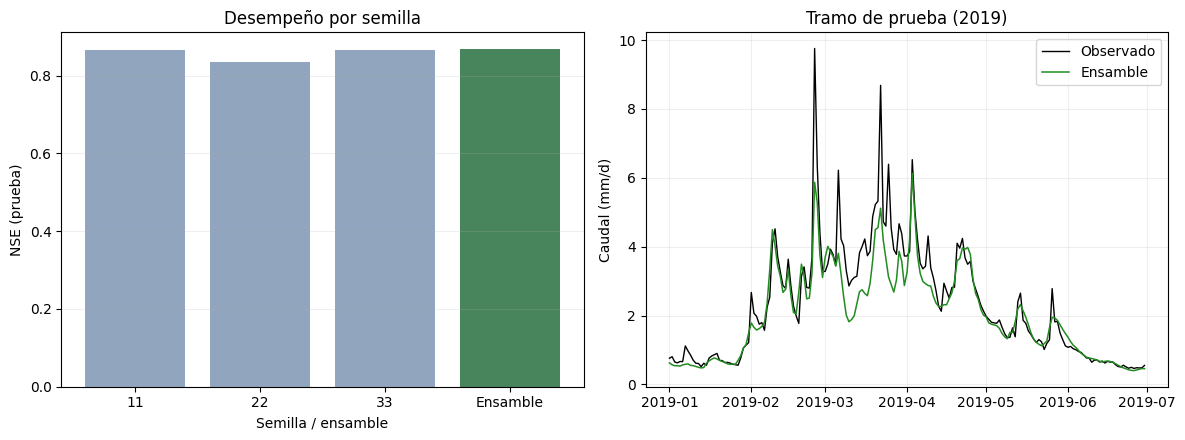

**Interpretación E3.** NSE medio de las tres semillas: **0.856**; desviación estándar: **0.018**. El ensamble obtuvo NSE **0.868**. La dispersión entre semillas mide la sensibilidad a la inicialización; una única prueba no demuestra estabilidad en otras particiones o años.

In [ ]:
# 5.1 Tres semillas y predicción media del ensamble
preds_E3=[]
filas_E3=[]
for semilla in [11,22,33]:
    modelo,_=entrenar(layers.LSTM(32),Xs,ys,per_s,semilla=semilla)
    pred=a_caudal(modelo.predict(Xs[per_s['prueba']],verbose=0).ravel())
    preds_E3.append(pred)
    filas_E3.append({'Modelo':f'LSTM · semilla {semilla}',
                     'NSE':nse(obs_te,pred),'KGE':kge(obs_te,pred)})

pred_ensamble=np.mean(np.vstack(preds_E3),axis=0)
filas_E3.append({'Modelo':'Ensamble (promedio 3)','NSE':nse(obs_te,pred_ensamble),
                 'KGE':kge(obs_te,pred_ensamble)})
tabla_E3=pd.DataFrame(filas_E3)
display(tabla_E3.round(3))
tabla_E3.to_csv(DIRECTORIO_RESULTADOS/'04_ejercicio3_ensamble.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(12,4.5))
axs[0].bar(range(len(tabla_E3)),tabla_E3.NSE,color=['#91A6BE']*3+['#48855C'])
axs[0].set_xticks(range(len(tabla_E3)),['11','22','33','Ensamble'])
axs[0].set_ylabel('NSE (prueba)');axs[0].set_xlabel('Semilla / ensamble')
axs[0].set_title('Desempeño por semilla');axs[0].grid(axis='y',alpha=.2)
tr=(fechas_s[per_s['prueba']] >= '2019-01-01') & (fechas_s[per_s['prueba']] <= '2019-06-30')
axs[1].plot(fechas_s[per_s['prueba']][tr],obs_te[tr],color='k',lw=1,label='Observado')
axs[1].plot(fechas_s[per_s['prueba']][tr],pred_ensamble[tr],color='forestgreen',lw=1.1,label='Ensamble')
axs[1].set_title('Tramo de prueba (2019)');axs[1].set_ylabel('Caudal (mm/d)');axs[1].legend();axs[1].grid(alpha=.2)
plt.tight_layout();fig.savefig(DIRECTORIO_RESULTADOS/'04_ejercicio3_ensamble.png',dpi=160);plt.show()

nse_ind=tabla_E3.NSE.iloc[:3]
display(Markdown(f'**Interpretación E3.** NSE medio de las tres semillas: '
                 f'**{nse_ind.mean():.3f}**; desviación estándar: **{nse_ind.std(ddof=1):.3f}**. '
                 f'El ensamble obtuvo NSE **{tabla_E3.NSE.iloc[-1]:.3f}**. '
                 'La dispersión entre semillas mide la sensibilidad a la inicialización; '
                 'una única prueba no demuestra estabilidad en otras particiones o años.'))

## 6. Práctica A2 y ejercicio 4: horizonte de pronóstico

En la práctica A2 del docente se agregan dos canales a la meteorología: `q_entrada` (caudal observado y, si falta, caudal simulado) y `q_bandera` (1 para observado y 0 para simulado). La LSTM predice el **cambio** `Δ = log(Q[t+H]+0.05) − log(Q[t]+0.05)` en horizontes de 1, 3 y 7 días, con ventana de 90 días.

**Consigna del ejercicio 4:** ampliar la evaluación al **horizonte de 14 días** y comparar con persistencia. Adicionalmente, para **H = 1 día** se entrena otro modelo que predice directamente el log-caudal (sin la transformación a Δ).

Pronóstico: H = 1 día(s)
LSTM · semilla 42 · 40 épocas · 85.4 s
Pronóstico: H = 3 día(s)
LSTM · semilla 42 · 36 épocas · 74.7 s
Pronóstico: H = 7 día(s)
LSTM · semilla 42 · 14 épocas · 26.8 s
Pronóstico: H = 14 día(s)
LSTM · semilla 42 · 10 épocas · 19.3 s


Modelo,LSTM,PISCO-ARNOVIC,Persistencia
Horizonte (días),,,
1,0.946,0.814,0.851
3,0.759,0.814,0.642
7,0.615,0.814,0.462
14,0.441,0.814,0.242


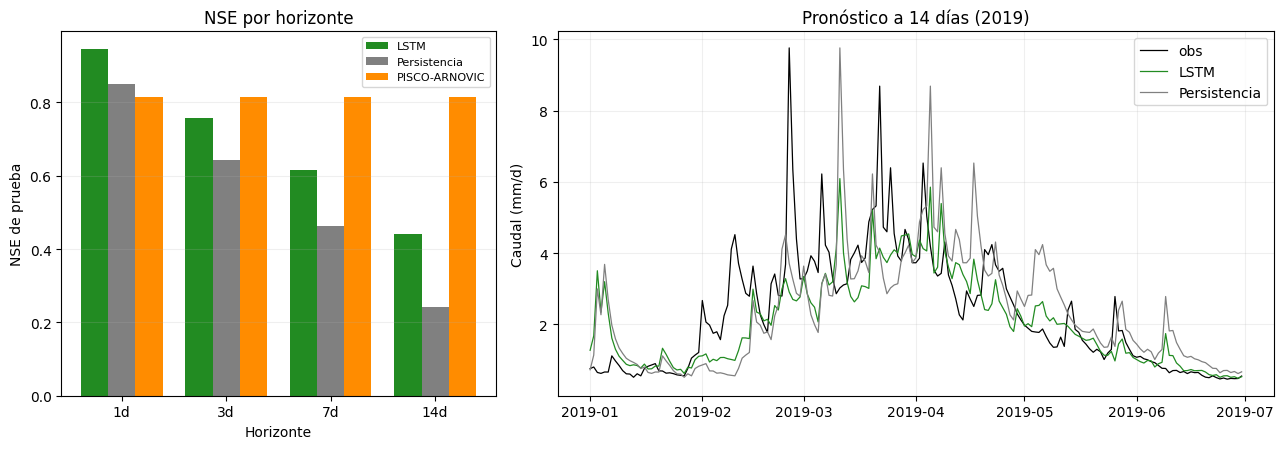

In [ ]:
# 6.1 Entradas A2: meteorología + log-caudal disponible + bandera de observación
# Los caudales de entrada proceden exclusivamente de fechas presentes o pasadas (<= t).
q_entrada_series=df['flow_obs'].fillna(df['flow_sim'])
if q_entrada_series.isna().any():
    # Los huecos residuales se resuelven solo con información anterior (ffill).
    q_entrada_series=q_entrada_series.ffill().fillna(max(np.exp(q_media)-0.05,0))
q_entrada=np.log(q_entrada_series.to_numpy(dtype=float)+0.05)
q_entrada_n=(q_entrada-q_media)/q_desv
q_bandera=df['flow_obs'].notna().values.astype('float32')
X_pron=np.column_stack([X_met_n,q_entrada_n,q_bandera]).astype('float32')
VENTANA_PRON = 90

resultados_pron = {}
filas_E4=[]
for H in [1,3,7,14]:
    Xp,tp,fechas_p,per_p=crear_ventanas(X_pron,VENTANA_PRON,horizonte=H)
    base=q_entrada_n[tp]
    yp=(q_n[tp+H]-base).astype('float32')
    print(f'Pronóstico: H = {H} día(s)')
    modelo,_=entrenar(layers.LSTM(32),Xp,yp,per_p)
    p=per_p['prueba']
    obs=q_obs[tp+H][p]
    pred=a_caudal(modelo.predict(Xp[p],verbose=0).ravel()+base[p])
    pers=a_caudal(base[p])
    arnovic=df.flow_sim.to_numpy()[tp+H][p]
    resultados_pron[H]={'fechas':fechas_p[p], 'obs':obs,'LSTM':pred,
                         'Persistencia':pers,'PISCO-ARNOVIC':arnovic}
    for nombre,serie in [('LSTM',pred),('Persistencia',pers),('PISCO-ARNOVIC',arnovic)]:
        filas_E4.append({'Horizonte (días)':H,'Modelo':nombre,
                         'NSE':nse(obs,serie),'KGE':kge(obs,serie)})
    if H==1:
        Xp1,tp1,fechas_p1,per_p1=Xp,tp,fechas_p,per_p

# Tabla y comparación de horizontes
tabla_E4=pd.DataFrame(filas_E4)
display(tabla_E4.pivot(index='Horizonte (días)',columns='Modelo',values='NSE').round(3))
tabla_E4.to_csv(DIRECTORIO_RESULTADOS/'05_ejercicio4_horizontes.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(13,4.6),gridspec_kw={'width_ratios':[1,1.65]})
horizontes=[1,3,7,14]; x=np.arange(len(horizontes)); ancho=.26
for j,(nombre,color) in enumerate([('LSTM','forestgreen'),('Persistencia','gray'),('PISCO-ARNOVIC','darkorange')]):
    valores=[nse(resultados_pron[h]['obs'],resultados_pron[h][nombre]) for h in horizontes]
    axs[0].bar(x+(j-1)*ancho,valores,ancho,color=color,label=nombre)
axs[0].set_xticks(x,[str(h)+'d' for h in horizontes]);axs[0].axhline(0,color='k',lw=.7)
axs[0].set_ylabel('NSE de prueba');axs[0].set_xlabel('Horizonte')
axs[0].set_title('NSE por horizonte');axs[0].legend(fontsize=8);axs[0].grid(axis='y',alpha=.2)
r=resultados_pron[14]; tramo=(r['fechas']>='2019-01-01') & (r['fechas']<='2019-06-30')
for nombre,color in [('obs','black'),('LSTM','forestgreen'),('Persistencia','gray')]:
    axs[1].plot(r['fechas'][tramo],r[nombre][tramo],color=color,lw=.9,label=nombre)
axs[1].set_title('Pronóstico a 14 días (2019)');axs[1].set_ylabel('Caudal (mm/d)')
axs[1].legend();axs[1].grid(alpha=.2)
plt.tight_layout();fig.savefig(DIRECTORIO_RESULTADOS/'05_ejercicio4_horizonte14.png',dpi=160);plt.show()

LSTM · semilla 42 · 37 épocas · 72.3 s


,Enfoque,NSE,KGE
0,LSTM · cambio Δ,0.946,0.944
1,LSTM · directo,0.944,0.923
2,Persistencia,0.851,0.926


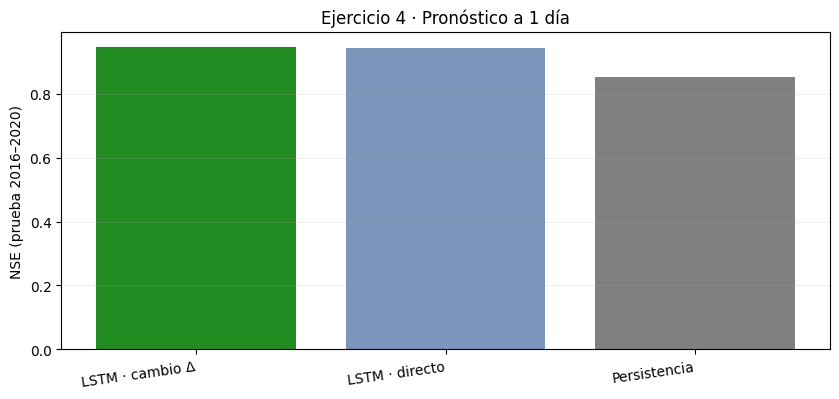

**Interpretación E4.** Para 14 días, la diferencia NSE **LSTM − persistencia** fue **+0.200**. A 1 día, la diferencia **LSTM-Δ − LSTM directa** fue **+0.003**. El signo de cada diferencia determina cuál alternativa funcionó mejor en esta cuenca y partición temporal.

In [ ]:
# 6.2 Contraste a 1 día: predicción directa versus predicción del cambio Δ
# Se mantienen exactamente las mismas entradas y el mismo período de prueba.
y_directo=q_n[tp1+1].astype('float32')
modelo_directo,hist_directo=entrenar(layers.LSTM(32),Xp1,y_directo,per_p1)
p=per_p1['prueba']
obs_1d=q_obs[tp1+1][p]
pred_directo=a_caudal(modelo_directo.predict(Xp1[p],verbose=0).ravel())
pred_delta=resultados_pron[1]['LSTM']
pers=resultados_pron[1]['Persistencia']

tabla_directa=pd.DataFrame([
    {'Enfoque':'LSTM · cambio Δ','NSE':nse(obs_1d,pred_delta),'KGE':kge(obs_1d,pred_delta)},
    {'Enfoque':'LSTM · directo','NSE':nse(obs_1d,pred_directo),'KGE':kge(obs_1d,pred_directo)},
    {'Enfoque':'Persistencia','NSE':nse(obs_1d,pers),'KGE':kge(obs_1d,pers)},
])
display(tabla_directa.round(3))
tabla_directa.to_csv(DIRECTORIO_RESULTADOS/'06_ejercicio4_delta_vs_directo.csv',index=False)

fig,ax=plt.subplots(figsize=(8.5,4.1))
ax.bar(tabla_directa['Enfoque'],tabla_directa.NSE,color=['forestgreen','#7B95BB','gray'])
ax.set_ylabel('NSE (prueba 2016–2020)');ax.set_title('Ejercicio 4 · Pronóstico a 1 día')
ax.grid(axis='y',alpha=.2);plt.xticks(rotation=8,ha='right');plt.tight_layout()
fig.savefig(DIRECTORIO_RESULTADOS/'06_ejercicio4_delta_vs_directo.png',dpi=160);plt.show()

h14=resultados_pron[14]
d14=nse(h14['obs'],h14['LSTM'])-nse(h14['obs'],h14['Persistencia'])
d1=nse(obs_1d,pred_delta)-nse(obs_1d,pred_directo)
display(Markdown(f'**Interpretación E4.** Para 14 días, la diferencia NSE '
                 f'**LSTM − persistencia** fue **{d14:+.3f}**. '
                 f'A 1 día, la diferencia **LSTM-Δ − LSTM directa** fue **{d1:+.3f}**. '
                 'El signo de cada diferencia determina cuál alternativa funcionó mejor '
                 'en esta cuenca y partición temporal.'))

## 7. Síntesis de resultados

Se integran los resultados de los 4 ejercicios, calculados con el conjunto de prueba **2016–2020**. Para cada comparación se mantienen los parámetros y la información de entrada descritos en su sección.

In [ ]:
# 7.1 Resumen final de los cuatro ejercicios
mejor1=tabla_E1.loc[tabla_E1.NSE.idxmax()]
media_semillas=tabla_E3.NSE.iloc[:3].mean()
desv_semillas=tabla_E3.NSE.iloc[:3].std(ddof=1)

resumen = f"""### Resultados · Cuenca {CUENCA}, estación {ESTACION} ({GAUGE})

**Ejercicio 1 — Memoria de la cuenca.** La configuración de mayor NSE corresponde a
{mejor1.Modelo}, ventana de {int(mejor1['Ventana (días)'])} días, con NSE = {mejor1.NSE:.3f}.
La variación del NSE entre ventanas indica sensibilidad a la información meteorológica antecedente.

**Ejercicio 2 — Variables cíclicas.** La LSTM de seis variables alcanzó NSE =
{tabla_E2.NSE.iloc[0]:.3f}; la LSTM con seno/coseno alcanzó NSE = {tabla_E2.NSE.iloc[1]:.3f}.
Diferencia = {delta_E2:+.3f}.

**Ejercicio 3 — Ensamble.** El NSE promedio de las tres semillas fue {media_semillas:.3f}
(desviación estándar = {desv_semillas:.3f}); el ensamble obtuvo NSE = {tabla_E3.NSE.iloc[-1]:.3f}.

**Ejercicio 4 — Horizonte.** A 14 días, NSE de la LSTM =
{nse(h14['obs'],h14['LSTM']):.3f} y NSE de persistencia =
{nse(h14['obs'],h14['Persistencia']):.3f}. A un día, NSE del enfoque Δ =
{nse(obs_1d,pred_delta):.3f} y NSE del enfoque directo = {nse(obs_1d,pred_directo):.3f}.

**Limitación.** Los resultados dependen de la disponibilidad y calidad de caudales observados,
los forzantes meteorológicos y el período de evaluación. No se infieren propiedades físicas
únicamente a partir de la importancia de una ventana o de un indicador estadístico.
"""
display(Markdown(resumen))
(DIRECTORIO_RESULTADOS/'07_sintesis_resultados.md').write_text(resumen,encoding='utf-8')
# Exportación de las tablas y figuras, sin incorporar datos de otras cuencas
import zipfile
paquete = RAIZ / 'Resultados_Lab9_3_Chancay_Lambayeque.zip'
with zipfile.ZipFile(paquete,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(DIRECTORIO_RESULTADOS.iterdir()):
        if f.is_file(): z.write(f,arcname=f.name)
print('Carpeta de resultados:',DIRECTORIO_RESULTADOS)
print('Archivo con los resultados:',paquete)

### Resultados · Cuenca Chancay–Lambayeque, estación Racarumi (PE_200907)

**Ejercicio 1 — Memoria de la cuenca.** La configuración de mayor NSE corresponde a
RNN, ventana de 365 días, con NSE = 0.860.
La variación del NSE entre ventanas indica sensibilidad a la información meteorológica antecedente.

**Ejercicio 2 — Variables cíclicas.** La LSTM de seis variables alcanzó NSE =
0.858; la LSTM con seno/coseno alcanzó NSE = 0.881.
Diferencia = +0.023.

**Ejercicio 3 — Ensamble.** El NSE promedio de las tres semillas fue 0.856
(desviación estándar = 0.018); el ensamble obtuvo NSE = 0.868.

**Ejercicio 4 — Horizonte.** A 14 días, NSE de la LSTM =
0.441 y NSE de persistencia =
0.242. A un día, NSE del enfoque Δ =
0.946 y NSE del enfoque directo = 0.944.

**Limitación.** Los resultados dependen de la disponibilidad y calidad de caudales observados,
los forzantes meteorológicos y el período de evaluación. No se infieren propiedades físicas
únicamente a partir de la importancia de una ventana o de un indicador estadístico.


Carpeta de resultados: /content/resultados_chancay_lambayeque
Archivo con los resultados: /content/Resultados_Lab9_3_Chancay_Lambayeque.zip


### 7.2 Discusión integrada de los resultados

A partir de los datos de la estación Racarumi, en la cuenca Chancay–Lambayeque, se compararon diferentes configuraciones de RNN y LSTM para la simulación y predicción del caudal.

| Ejercicio | Mejor resultado destacado | NSE |
|---|---|---:|
| 1. Memoria temporal | RNN de 365 días | 0.860 |
| 2. Variables adicionales | LSTM con variables estacionales | 0.881 |
| 3. Ensamble | Promedio de tres LSTM | 0.868 |
| 4. Pronóstico a 1 día | LSTM con cambio Δ | 0.946 |
| 4. Pronóstico a 14 días | LSTM con cambio Δ | 0.441 |

En los primeros ejercicios se observó que aumentar la ventana temporal no siempre mejora las predicciones. En cambio, incorporar variables estacionales permitió obtener mejores resultados, alcanzando un NSE de 0.881. El ensamble también presentó un buen desempeño, aunque su mejora fue pequeña.

Respecto al pronóstico, la LSTM obtuvo mejores resultados para horizontes cortos. A medida que aumentaron los días de anticipación, su desempeño disminuyó, aunque se mantuvo por encima del método de persistencia.

**En conclusión**, los resultados muestran que las LSTM son útiles para modelar el comportamiento del caudal, pero su desempeño depende de las variables utilizadas, la ventana temporal y el horizonte de predicción. Además, un modelo más complejo no necesariamente produce mejores resultados.


## 8. Referencias

- Notebook base del curso: **Lab9_3_RNN_LSTM_Peru_v2.ipynb**, sección 4, Prácticas A1 y A2, y ejercicios 1–4.
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M. y Lavado-Casimiro, W. (2026). *CAMELS-PE: Catchment Attributes and Meteorology for Large-sample Studies in Peru* (v1.0.1). Zenodo. https://doi.org/10.5281/zenodo.21195425
- Base de comparación hidrológica: PISCO-ARNOVIC (serie `flow_sim` provista en CAMELS-PE).

**Delimitación:** el análisis corresponde exclusivamente a **Chancay–Lambayeque, estación Racarumi (`PE_200907`)**; Huatiapa se mantiene únicamente como referencia metodológica de la clase y no se emplea en los cálculos.